---
title: "Getting the data"
subtitle: "Download hindcasts, the forecast and observations, then check what arrived"
description: "Download CFSv2 and CHIRPS data with PyCPT's download_data, check available years, inspect files and units, and reconcile the values with an independent calculation."
execute:
  enabled: false
---

This chapter downloads the three datasets that the
[first chapter](01-first-case.ipynb) described: CFSv2 hindcasts for September
starts 1991-2020, the CFSv2 forecast started on 1 September 2023, and observed
OND rainfall from the catalog entry `UCSB.PRCP`. Then it checks what arrived:
which years, which grid, which units and which values.

Every number on this page comes from the executed cells below.

::: {.callout-note title="What you need to run this page"}
The full PyCPT environment and internet access to the IRI Data Library. The
download time depends on the Data Library server and your connection; it is
printed when the cell runs. The comparison in step 7 also reads saved files
from this tutorial's repository and is skipped if they are not present.
:::

## 1. Repeat the case settings

Each chapter is a separate notebook, so the settings from chapter 1 are repeated
here unchanged. `force_download=True` makes PyCPT fetch fresh copies even if
files with the same names exist; chapter 1 showed why that matters.

In [1]:
from contextlib import redirect_stdout
from pathlib import Path
import datetime as dt
import inspect
import io
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
import cptdl as dl
import pycpt
from pycpt import notebook as pycpt_notebook

tutorial_root = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pycpt_tutorial").is_dir()), None)
sys.path.insert(0, str(tutorial_root))
from pycpt_tutorial import figures
figures.use_style()

MOS = "CCA"
predictor_names = ["CFSv2.PRCP"]
predictand_name = "UCSB.PRCP"
local_predictand_file = None

download_args = {
    "fdate": dt.datetime(2023, 9, 1),
    "target": "Oct-Dec",
    "target_first_year": 1991,
    "target_final_year": 2020,
    "predictor_extent": {"west": 85, "east": 155, "south": -20, "north": 20},
    "predictand_extent": {"west": 94, "east": 142, "south": -12, "north": 7},
}
force_download = True

case_dir = Path.home() / "PyCPT" / "indonesia-ond-2023-sep-init"
domain_dir = pycpt.setup(case_dir, download_args["predictor_extent"])

Input data will be saved in ~/PyCPT/indonesia-ond-2023-sep-init/85W-155E_to_-20S-20N/data
Figures will be saved in ~/PyCPT/indonesia-ond-2023-sep-init/85W-155E_to_-20S-20N/figures
Output will be saved in ~/PyCPT/indonesia-ond-2023-sep-init/85W-155E_to_-20S-20N/output


## 2. Does this download use your IRI key?

The [authentication guide](https://iri-pycpt.github.io/authentication/) explains
that some Data Library datasets require a key. Whether a particular call *sends*
one is a question about the code, so we read it. In PyCPT 2.10.4,
`download_data` reaches the network through `cached_download`, which calls
`cptdl.download`; that function forwards `use_dlauth` to `simple_download`,
which attaches the key cookie only when `use_dlauth` is `True`. The cell prints
those lines from the installed source.

In [2]:
def show_lines(function, words):
    source = inspect.getsource(function).splitlines()
    print(f"--- {function.__module__}.{function.__name__}")
    for number, line in enumerate(source, start=1):
        if any(word in line for word in words):
            print(f"{number:4d} | {line}")


show_lines(pycpt_notebook.cached_download, ["dl.download(", "force_download"])
show_lines(dl.download, ["def download", "simple_download("])
show_lines(dl.simple_download, ["def simple_download", "use_dlauth", "cookies"])

--- pycpt.notebook.cached_download
   1 | def cached_download(url_pattern, files_root, basename, force_download, download_args):
   6 |     if not ncfile.is_file() or force_download:
   8 |         ds = dl.download(
--- cptdl.utilities.download
   1 | def download(baseurl, dest, verbose=False, use_dlauth=False, **kwargs):
  12 |     path = simple_download(url, dest, verbose=verbose, use_dlauth=use_dlauth)
--- cptdl.utilities.simple_download
   1 | def simple_download(url, dest, verbose=False, use_dlauth=False):
   4 |     if str(use_dlauth) == 'True':
   6 |         assert dlauthid is not None, "You need to use cpttools.setup_dlauth('your_email') to get a cookie before you can download this data! or, you can try setting use_dlauth=False"
   7 |         cookies = {'__dlauth_id': dlauthid}
   9 |         cookies={}
  10 |     with requests.post(url, stream=True, allow_redirects=True, cookies=cookies) as r:


`cached_download` passes no `use_dlauth` argument, so the default `False`
applies and no cookie is sent. To confirm this at run time, the next cell
counts attempts to open any file whose name contains `dlauth`, the name PyCPT
uses for the stored key. It only counts; it never reads a file.

In [3]:
credential_file_opens = {"count": 0}


def count_credential_opens(event, args):
    if event == "open" and isinstance(args[0], (str, bytes)) and "dlauth" in str(args[0]).lower():
        credential_file_opens["count"] += 1


sys.addaudithook(count_credential_opens)
print("Counting credential-file opens from here on.")

Counting credential-file opens from here on.


## 3. Download

`download_data` returns three things: the observations `Y`, a list of hindcast
arrays (one per model) and a list of forecast arrays. PyCPT prints the URL of
each request and a progress bar. The cell keeps the URLs and drops the progress
bars, which are only screen updates.

In [4]:
log = io.StringIO()
start = time.monotonic()
with redirect_stdout(log):
    Y, hindcast_data, forecast_data = pycpt.download_data(
        predictand_name, local_predictand_file, predictor_names,
        download_args, domain_dir, force_download)
elapsed = time.monotonic() - start

for line in log.getvalue().replace("\r", "\n").splitlines():
    if line.strip() and not line.startswith("DOWNLOADING:"):
        print(line)
print(f"\nDownload time: {elapsed:.0f} s")
print("Credential-file opens during the download:", credential_file_opens["count"])

URL: https://iridl.ldeo.columbia.edu/SOURCES/.Models/.NMME/.NCEP-CFSv2/.HINDCAST/.PENTAD_SAMPLES_FULL/.prec/S/%280000%201%20Sep%202023%29/VALUES/L/1.5/3.5/RANGEEDGES/%5BL%5D//keepgrids/average/Y/-20/20/RANGEEDGES/X/85/155/RANGEEDGES/%5BM%5D/average/92/mul/-999/setmissing_value/%5BX/Y%5D%5BL/S/add%5D/cptv10.tsv
URL: https://iridl.ldeo.columbia.edu/SOURCES/.UCSB/.CHIRPS/.v2p0/.daily-improved/.global/.0p25/.prcp/92/mul/T/(1%20Jan%201991)/(31%20Dec%202020)/RANGE/T/%28Oct-Dec%201991-2020%29/seasonalAverage/Y/%28-12%29/%287%29/RANGEEDGES/X/%2894%29/%28142%29/RANGEEDGES/-999/setmissing_value/%5BX/Y%5D%5BT%5Dcptv10.tsv
URL: https://iridl.ldeo.columbia.edu/SOURCES/.Models/.NMME/.NCEP-CFSv2/.HINDCAST/.PENTAD_SAMPLES_FULL/.prec/S/%280000%201%20Sep%201991-2020%29/VALUES/L/1.5/3.5/RANGEEDGES/%5BL%5D//keepgrids/average/Y/-20/20/RANGEEDGES/X/85/155/RANGEEDGES/%5BM%5D/average/92/mul/-999/setmissing_value/%5BX/Y%5D%5BL/S/add%5D/cptv10.tsv

Download time: 322 s
Credential-file opens during the download:

PyCPT requested the forecast first, then the observations, then the hindcasts.
The credential count confirms the reading of the source: these three public
requests did not use the key. A dataset that requires a key needs a different
route; check the authentication guide before relying on this behaviour.

One more observation from 10 November 2026: opening Data Library pages in a web
browser showed a sign-in screen stating that the Data Library now requires all
users to sign in, while the PyCPT data requests on this page still succeeded
without a key. If your downloads fail with an authentication error, set up the
key as the authentication guide describes.

## 4. Check the training years

`summarize_available_years` lines up the target years of the observations and of
each model's hindcasts against the training period, and reports whether the
forecast arrived. It is the template's guard against silently training on
fewer years than you asked for.

In [5]:
pycpt.summarize_available_years(predictor_names, predictand_name, download_args,
                                Y, hindcast_data, forecast_data)

,UCSB.PRCP,CFSv2.PRCP
1991,ok,ok
1992,ok,ok
1993,ok,ok
1994,ok,ok
1995,ok,ok
1996,ok,ok
1997,ok,ok
1998,ok,ok
1999,ok,ok
2000,ok,ok


,CFSv2.PRCP
2023,ok


## 5. What landed on disk

Each dataset is saved twice in `data/`: the text file returned by the Data
Library (`.tsv`, CPT format) and a NetCDF copy written by PyCPT (`.nc`). Later
runs with `force_download=False` read the `.nc` file.

In [6]:
files = sorted((domain_dir / "data").iterdir())
pd.DataFrame({"file": [f.name for f in files],
              "size (kB)": [round(f.stat().st_size / 1000) for f in files]})

,file,size (kB)
0,CCSM4.PRCP.nc,713
1,CCSM4.PRCP.tsv,1248
2,CCSM4.PRCP_f2023.nc,37
3,CCSM4.PRCP_f2023.tsv,42
4,CESM1.PRCP.nc,713
5,CESM1.PRCP.tsv,1248
6,CESM1.PRCP_f2023.nc,37
7,CESM1.PRCP_f2023.tsv,42
8,CFSv2.PRCP.nc,713
9,CFSv2.PRCP.tsv,1248


## 6. Inspect the arrays

Before fitting anything, look at the dimensions, dates, grid, units and missing
values of each array.

In [7]:
X = hindcast_data[0]
F = forecast_data[0]


def describe(label, a):
    return {
        "array": label,
        "variable": a.name,
        "shape (T, Y, X)": tuple(a.sizes[d] for d in ("T", "Y", "X")),
        "first T": str(a["T"].values[0])[:16],
        "last T": str(a["T"].values[-1])[:16],
        "season (Ti to Tf)": f"{str(a['Ti'].values[0])[:10]} to {str(a['Tf'].values[0])[:10]}",
        "initialization S": str(a["S"].values[0])[:10] if "S" in a.coords else "none",
        "grid spacing (deg)": float(abs(a["X"].diff("X")).mean()),
        "longitude range": f"{float(a['X'].min())} to {float(a['X'].max())}",
        "latitude range": f"{float(a['Y'].min())} to {float(a['Y'].max())}",
        "units attribute": a.attrs.get("units"),
        "min": round(float(a.min()), 2),
        "max": round(float(a.max()), 2),
        "missing (%)": round(100 * float(a.isnull().mean()), 1),
    }


inventory = pd.DataFrame([describe("Y observations", Y),
                          describe("X hindcasts", X),
                          describe("F forecast", F)]).set_index("array").T
inventory

array,Y observations,X hindcasts,F forecast
variable,prcp,prec,prec
"shape (T, Y, X)","(30, 76, 192)","(30, 41, 71)","(1, 41, 71)"
first T,1991-11-15T12:00,1991-11-15T12:00,2023-11-15T12:00
last T,2020-11-15T12:00,2020-11-15T12:00,2023-11-15T12:00
season (Ti to Tf),1991-10-01 to 1991-12-31,1991-10-01 to 1991-12-31,2023-10-01 to 2023-12-31
initialization S,none,1991-09-01,2023-09-01
grid spacing (deg),0.25,1.0,1.0
longitude range,94.125 to 141.875,85.0 to 155.0,85.0 to 155.0
latitude range,-11.875 to 6.875,-20.0 to 20.0,-20.0 to 20.0
units attribute,mm/day,mm/day,mm/day


Points to read from the table:

- **Dates.** `T` is the midpoint of each season (15 November, 12:00). `Ti` and
  `Tf` give the first and last day of the season. `S` is the initialization date;
  observations have none.
- **Grids.** The model fields are on a 1° grid over the predictor box. The
  observations are on a 0.25° grid of cell centres inside the predictand box.
- **Missing values.** The model fields have none. The observation field is missing
  at the share of cells shown; the map in step 8 shows where.
- **Units.** All three arrays carry the attribute `mm/day`, but the values range up
  to thousands. Step 7 checks what they really are.

In [8]:
complete_obs_cells = int(Y.notnull().all("T").sum())
print(f"Observation cells with values in all {Y.sizes['T']} seasons: {complete_obs_cells}")
print(f"Observation cells with no values at all: {int(Y.isnull().all('T').sum())}")

Observation cells with values in all 30 seasons: 3885
Observation cells with no values at all: 10707


## 7. Units: check the values, not the label

Chapter 1 showed that every URL multiplies by 92, the number of days in OND. If
the values are seasonal totals in mm, the downloaded CFSv2 hindcasts should equal
the **mean of the three monthly rainfall rates (mm/day) multiplied by 92**.

This tutorial's research archive kept the CFSv2 monthly rates for October,
November and December from the earlier seasonal benchmark, downloaded separately
from the same Data Library collection. They allow an independent check.

In [9]:
repo = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "research/cases").is_dir()), None)
audit_file = None if repo is None else (
    repo / "research/cases/indonesia-all-seasons-2021-2024-025deg/outputs/OND_monthly_audit.nc")

if audit_file is None or not audit_file.exists():
    print("Saved monthly rates not found; skipping the independent unit check.")
else:
    with xr.open_dataset(audit_file) as saved:
        saved = saved.load()
    rates = saved.precipitation_rate.rename(predictor_Y="Y", predictor_X="X")
    days = saved.target_month_days
    print("Saved rate units:", rates.attrs.get("units"),
          "| leads:", rates["lead"].values.tolist(),
          "| days per target month:", days.sel(season_year=1991).values.tolist(),
          "| ensemble members:", np.unique(saved.valid_member_count).tolist())

    training_years = X["T"].dt.year.values
    mean_times_92 = (rates.sel(season_year=training_years).mean("lead") * 92).values
    gap = np.abs(X.transpose("T", "Y", "X").values - mean_times_92)
    print(f"Hindcasts vs mean monthly rate x 92: largest difference {gap.max():.4f} mm "
          f"(relative {np.max(gap / mean_times_92):.1e})")

    forecast_check = (rates.sel(season_year=2023).mean("lead") * 92).values
    gap_f = np.abs(F.isel(T=0).transpose("Y", "X").values - forecast_check)
    print(f"Forecast vs mean monthly rate x 92:  largest difference {gap_f.max():.4f} mm")

Saved rate units: mm/day | leads: [1.5, 2.5, 3.5] | days per target month: [31, 30, 31] | ensemble members: [24.0]
Hindcasts vs mean monthly rate x 92: largest difference 0.0051 mm (relative 5.0e-06)
Forecast vs mean monthly rate x 92:  largest difference 0.0050 mm


The downloaded values match the mean monthly rate times 92 to within a few
thousandths of a millimetre, a size consistent with the limited precision of the
CPT text files the Data Library returns. So the arrays hold **seasonal rainfall
totals in mm**, and the `mm/day` attribute does not describe them. Label any plot
or score made from these arrays as mm per season.

### The same data, a slightly different total

The [Fit & diagnose](../chapters/fit-diagnose-2023.qmd) case used the same CFSv2
monthly rates, but weighted each month by its own length: 31 × October + 30 ×
November + 31 × December. PyCPT gives each month equal weight before multiplying by
92. The difference per cell is

$$
\tfrac{92}{3}(r_{Oct} + r_{Nov} + r_{Dec}) - (31\,r_{Oct} + 30\,r_{Nov} + 31\,r_{Dec})
= \tfrac{1}{3}\,(2\,r_{Nov} - r_{Oct} - r_{Dec}).
$$

The cell checks that formula against both saved datasets.

In [10]:
if audit_file is not None and audit_file.exists():
    case_x = xr.open_dataset(repo / "docs/data/fitting-2023/OND-X.nc").precipitation.load()
    case_f = xr.open_dataset(repo / "docs/data/fitting-2023/OND-F.nc").precipitation.load()
    r = rates.sel(season_year=training_years).transpose("season_year", "lead", "Y", "X").values
    predicted_gap = (2 * r[:, 1] - r[:, 0] - r[:, 2]) / 3
    actual_gap = X.transpose("T", "Y", "X").values - case_x.transpose("T", "Y", "X").values

    print(f"PyCPT hindcasts minus Fit & diagnose inputs: largest {np.abs(actual_gap).max():.2f} mm, "
          f"mean absolute {np.abs(actual_gap).mean():.2f} mm, "
          f"largest relative {np.max(np.abs(actual_gap) / case_x.values):.2%}")
    print(f"Formula vs actual difference: largest mismatch {np.abs(actual_gap - predicted_gap).max():.4f} mm")
    forecast_gap = np.abs(F.values - case_f.transpose("T", "Y", "X").values).max()
    print(f"PyCPT forecast minus Fit & diagnose forecast input: largest {forecast_gap:.2f} mm")

    case_y = xr.open_dataset(repo / "docs/data/fitting-2023/OND-Y.nc").precipitation
    same_grid = np.allclose(Y["X"], case_y["X"]) and np.allclose(Y["Y"], case_y["Y"])
    print("Observation grid identical to the Fit & diagnose observation grid:", same_grid)

PyCPT hindcasts minus Fit & diagnose inputs: largest 8.25 mm, mean absolute 0.84 mm, largest relative 1.79%
Formula vs actual difference: largest mismatch 0.0089 mm
PyCPT forecast minus Fit & diagnose forecast input: largest 5.17 mm


Observation grid identical to the Fit & diagnose observation grid: True


Both totals are correct descriptions of the same model output; they answer
slightly different arithmetic questions. The consequence for this tutorial is
concrete: the hindcasts PyCPT downloads are **not byte-for-byte the inputs of the
Fit & diagnose case**, so a fit in a later chapter can match those saved results
only approximately, by an amount we will measure there.

The observation grid is identical, but the product is not: `UCSB.PRCP` is CHIRPS
v2.0, while Fit & diagnose used CHIRPS v3.0. Chapter 3 brings in that local file.

## 8. Look at the fields

A map is the fastest check that nothing is shifted, flipped or empty. The panels
show the 1991-2020 average of the observed OND totals, the same average of the
CFSv2 hindcasts, and the 2023 forecast.

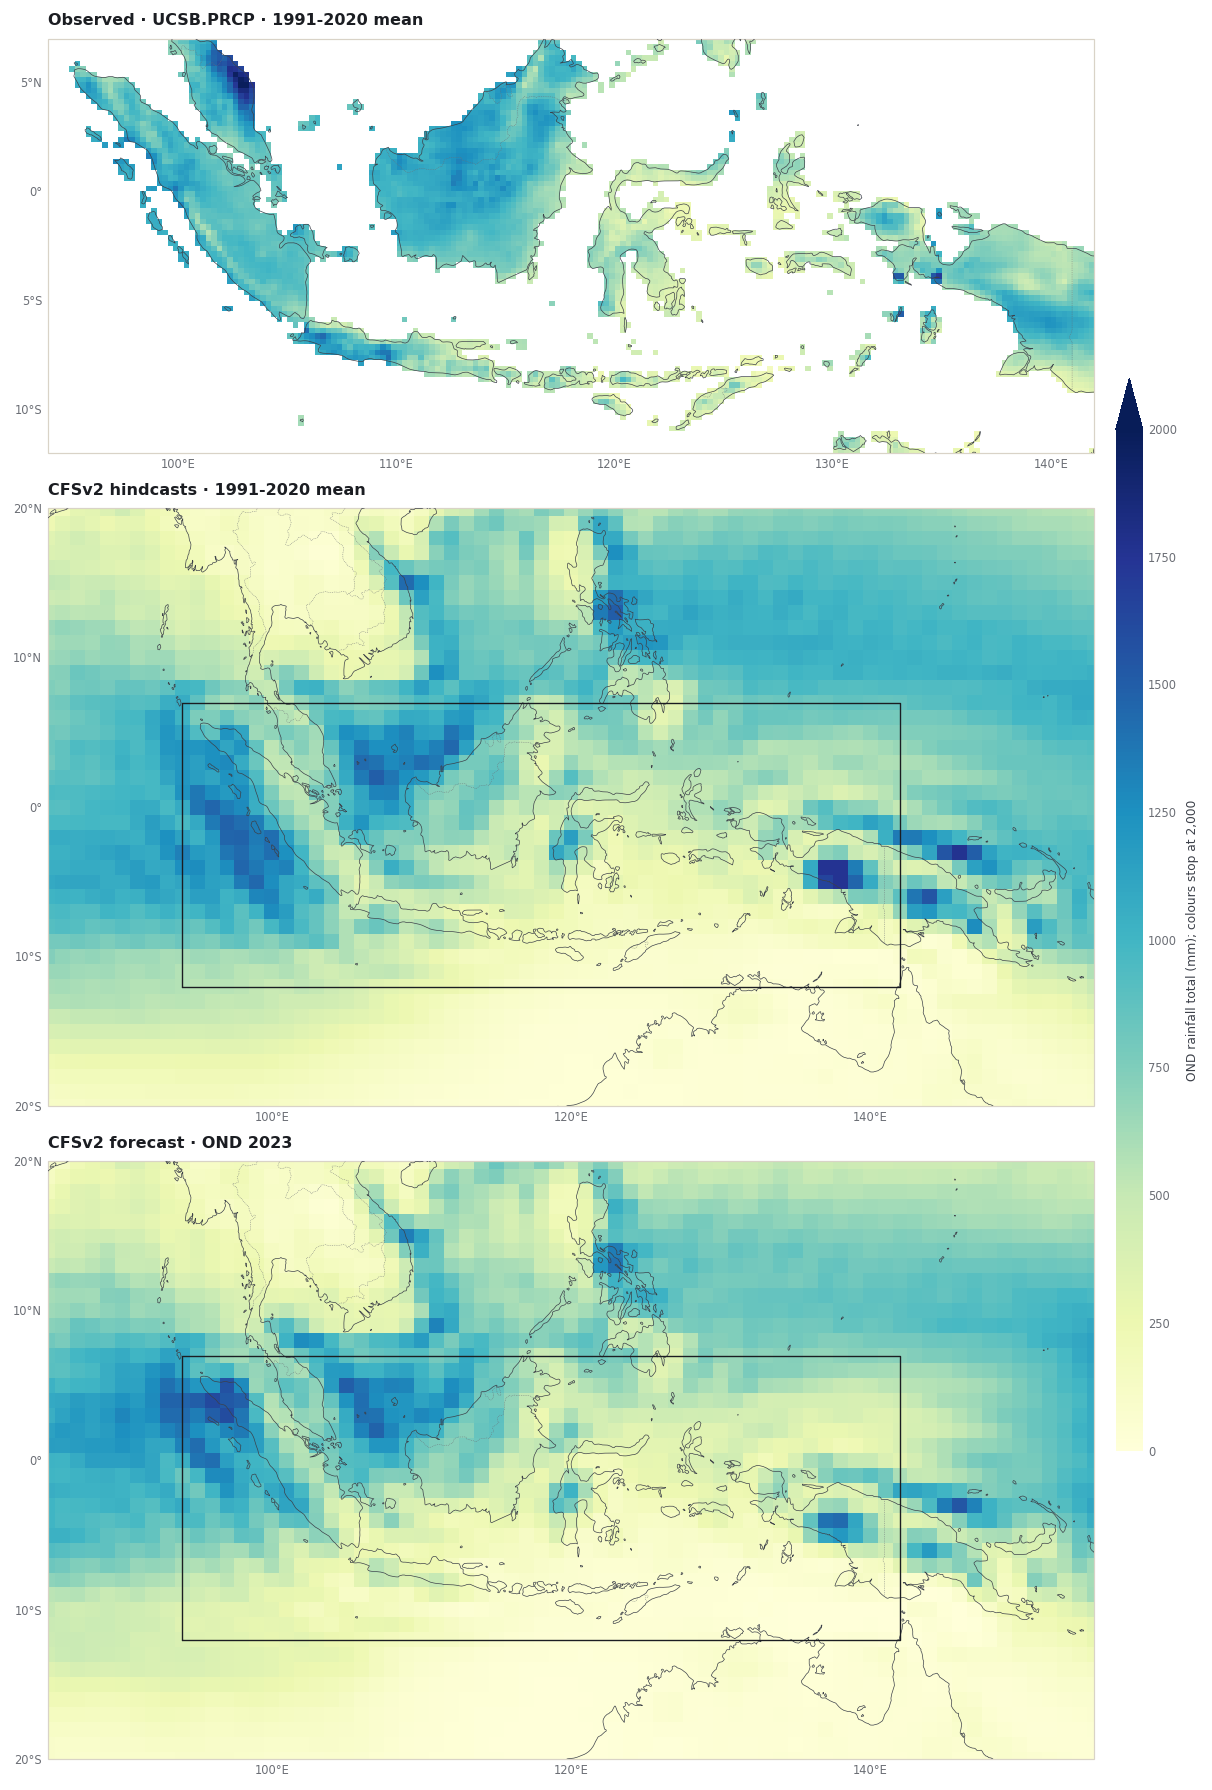

In [11]:
predictor_box = figures.extent_of(download_args["predictor_extent"])
predictand_box = figures.extent_of(download_args["predictand_extent"])
panels = [(Y.mean("T"), predictand_box, "Observed · UCSB.PRCP · 1991-2020 mean"),
          (X.mean("T"), predictor_box, "CFSv2 hindcasts · 1991-2020 mean"),
          (F.isel(T=0), predictor_box, "CFSv2 forecast · OND 2023")]

fig, grid = figures.stacked([figures.map_height(extent) for _, extent, _ in panels])
axes = []
for i, (field, extent, title) in enumerate(panels):
    ax = figures.map_axes(fig, grid[i, 0], extent)
    image = figures.draw_field(ax, field, cmap="YlGnBu", vmin=0, vmax=2000)
    if i > 0:
        figures.box(ax, predictand_box, figures.INK, linewidth=0.9)
    ax.set_title(title)
    axes.append(ax)
figures.colorbar(fig, image, axes, "OND rainfall total (mm); colours stop at 2,000", extend="max", fraction=0.025, aspect=40)
plt.show()

The observed field has values only over land; sea cells are the missing values
counted in step 6. The black outline on the model panels is the predictand box.
The model fields cover the whole predictor box, land and sea. All three panels
share one colour scale, which stops at 2,000 mm; cells above it take the darkest
colour.

## What you have now

- Observations, hindcasts and a forecast in the case folder, as `.tsv` and `.nc`.
- A year-by-year availability check for the training period.
- Evidence that these downloads did not use the IRI key.
- Evidence that the values are seasonal totals in mm despite the `mm/day` label.
- A measured difference between PyCPT's CFSv2 totals and the Fit & diagnose inputs,
  explained exactly by how the three months are weighted.

The next chapter replaces the catalog observations with the local CHIRPS v3.0 file
used by the case studies.

## References {.unnumbered .reference-section}

1. IRI. *PyCPT documentation: Authentication: downloading protected data*. <https://iri-pycpt.github.io/authentication/>
2. IRI. *PyCPT 2.10.4 source: `pycpt/src/pycpt/notebook.py`* (`setup`, `download_data`, `summarize_available_years`, `evaluate_models` and the plotting functions). Tag pycpt-2.10.4, commit 084bb5c. <https://github.com/iri-pycpt/pycpt/blob/084bb5c380c200b5f65f11ba224a965547b91da1/pycpt/src/pycpt/notebook.py>
3. IRI. *PyCPT 2.10.4 source: `cptdl`* (data catalog, `leads_from_target`, `evaluate_url`, `download`, `simple_download`). Tag pycpt-2.10.4, commit 084bb5c. <https://github.com/iri-pycpt/pycpt/tree/084bb5c380c200b5f65f11ba224a965547b91da1/pycpt/src/cptdl>
4. IRI. *PyCPT operational seasonal notebook* (`Operations/pycpt-operational.ipynb`). iri-pycpt/notebooks, commit 1c97531. <https://github.com/iri-pycpt/notebooks/blob/1c975316910b9e047ce685d9b8cdefb2c4b73551/Operations/pycpt-operational.ipynb>
5. IRI Data Library. *NMME NCEP-CFSv2 hindcasts, PENTAD_SAMPLES_FULL, precipitation*. <https://iridl.ldeo.columbia.edu/SOURCES/.Models/.NMME/.NCEP-CFSv2/.HINDCAST/.PENTAD_SAMPLES_FULL/.prec/> Browsing Data Library pages requires signing in (checked 10 November 2026); PyCPT's data requests in this tutorial succeeded without a key.
6. Saha, S., Moorthi, S., Wu, X., et al. (2014). The NCEP Climate Forecast System Version 2. *Journal of Climate*, 27(6), 2185-2208. <https://doi.org/10.1175/JCLI-D-12-00823.1>
7. Kirtman, B., Min, D., Infanti, J., et al. (2014). The North American Multimodel Ensemble: Phase-1 seasonal-to-interannual prediction; Phase-2 toward developing intraseasonal prediction. *Bulletin of the American Meteorological Society*, 95(4), 585-601. <https://doi.org/10.1175/BAMS-D-12-00050.1>
8. IRI Data Library. *UCSB CHIRPS version 2.0*. <https://iridl.ldeo.columbia.edu/SOURCES/.UCSB/.CHIRPS/.v2p0/> Browsing Data Library pages requires signing in (checked 10 November 2026); PyCPT's data requests in this tutorial succeeded without a key.
9. Funk, C., Peterson, P., Landsfeld, M., et al. (2015). The climate hazards infrared precipitation with stations: a new environmental record for monitoring extremes. *Scientific Data*, 2, 150066. <https://doi.org/10.1038/sdata.2015.66>
10. Natural Earth. *Admin 0: Countries*, 1:10m cultural vectors. <https://www.naturalearthdata.com/downloads/10m-cultural-vectors/10m-admin-0-countries/>
11. SciTools. *Cartopy* (documentation). <https://scitools.org.uk/cartopy/docs/latest/>